In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt 
%matplotlib inline

In [2]:
# read in all the words
words = open('names.txt', 'r').read().splitlines()
words[:8]

['emma', 'olivia', 'ava', 'isabella', 'sophia', 'charlotte', 'mia', 'amelia']

In [3]:
len(words)

32033

In [4]:
# build the vocab of chars and mapping to/from integers
chars = sorted(list(set(''.join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s, i in stoi.items()}
vocab_size = len(itos)
print(itos)
print(vocab_size)

{1: 'a', 2: 'b', 3: 'c', 4: 'd', 5: 'e', 6: 'f', 7: 'g', 8: 'h', 9: 'i', 10: 'j', 11: 'k', 12: 'l', 13: 'm', 14: 'n', 15: 'o', 16: 'p', 17: 'q', 18: 'r', 19: 's', 20: 't', 21: 'u', 22: 'v', 23: 'w', 24: 'x', 25: 'y', 26: 'z', 0: '.'}
27


In [5]:
# build the dataset
block_size = 3     # context lenght: how many chars do we take to predict the next one?

def build_dataset(words):
    X, Y = [], []
    for w in words:
        
        context = [0] * block_size
        for ch in w + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            context = context[1:] + [ix]      # crop and append
            
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    print(X.shape, Y.shape)
    return X, Y

import random
random.seed(42)
random.shuffle(words)
n1 = int(0.8*len(words))
n2 = int(0.9*len(words))

Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:])

torch.Size([182625, 3]) torch.Size([182625])
torch.Size([22655, 3]) torch.Size([22655])
torch.Size([22866, 3]) torch.Size([22866])


In [6]:
# MLP revisited
n_emb = 10         # the dimentionality of the chars embeding vectors
n_hidden = 200     # the number of neurons in the hidden layer of the MLP

g = torch.Generator().manual_seed(2147483647)              # for reproducibility
C = torch.randn((vocab_size, n_emb),                generator=g)
W1 = torch.randn((n_emb * block_size, n_hidden),    generator=g)
b1 = torch.randn(n_hidden,                          generator=g) 
W2 = torch.randn((n_hidden, vocab_size),            generator=g) 
b2 = torch.randn(vocab_size,                        generator=g) 


parametres = [C, W1, b1, W2, b2]
print(sum(p.nelement() for p in parametres)) # number of params in total
for p in parametres:
    p.requires_grad = True

11897


In [7]:
max_steps = 200000
batch_size = 32
lossi = []

for i in range(max_steps):
    
    # minibatch construct
    ix = torch.randint(0, Xtr.shape[0], (batch_size, ), generator=g)
    Xb, Yb = Xtr[ix], Ytr[ix]
    
    # forward pass
    emb = C[Xb]                                                  # (32, 3, 2)
    embcat = emb.view(emb.shape[0], -1)
    hpreact = embcat @ W1 +  b1
    
    h = torch.tanh(hpreact)                                     # (32, 100)
    logits = h @ W2 + b2                                        # (32, 27)
    loss = F.cross_entropy(logits, Yb)
    

    # backward pass
    for p in parametres:
        p.grad = None
    loss.backward()

    # update
    lr = 0.1 if i < 100000 else 0.01
    for p in parametres:
        p.data += -lr * p.grad
        
    # track stats
    if i % 10000 == 0 :
        print(f'{i:7d}/{max_steps:7d}: {loss.item():.4f}')
    lossi.append(loss.log10().item())
    
    break

# print(loss.item())

      0/ 200000: 27.8817


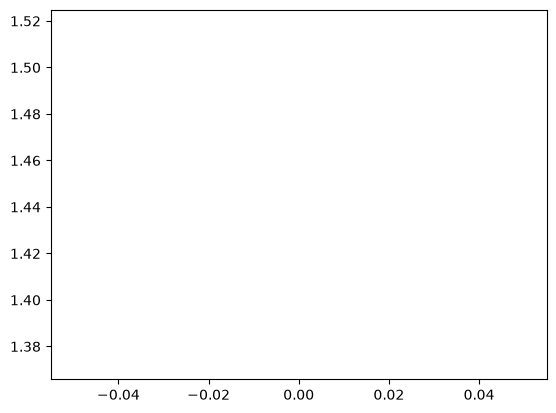

In [8]:
plt.plot(lossi)

In [9]:
# calibrate the batch norm at the end of training

with torch.no_grad():
    def split_loss(split):
        x,y = {
            'train': (Xtr, Ytr),
            'val': (Xdev, Ydev),
            'test': (Xte, Yte)
        }[split]
        emb = C[x] # (N, block_size, n_embd)
        embcat = emb.view(emb.shape[0], -1)
        h = torch.tanh(embcat @ W1 + b1)
        logits = h @ W2 + b2
        loss = F.cross_entropy(logits, y)
        print(split, loss.item())
    
split_loss('train')
split_loss('val')

train 25.167741775512695
val 25.140993118286133


In [ ]:
g = torch.Generator().manual_seed(2147483647)   